# Did the ad campaign lift conversion enough to justify spend?

A marketing team ran a randomized test: most users were shown an **ad**, while a holdout group saw a **public service announcement (PSA)** in the same slot instead. The business question is not only *"did the ad work?"* but *"did it work by enough to pay for the impressions?"*

**Data:** [Marketing A/B Testing (Kaggle)](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing). One row per user: test group (`ad` / `psa`), `converted` (made a purchase), total ads seen, and the day and hour on which the user saw the most ads. There are no cost or revenue fields.

| Section | Question |
|---|---|
| 1. Data audit | Is the file clean enough to trust? |
| 2. Experiment sanity check | Is the lopsided split a problem? Were both arms delivered alike? |
| 3. Primary test | How big is the lift, and how sure are we? |
| 4. Power analysis | What is the smallest lift this design could detect? |
| 5. Segments | Where does the lift come from, and which segment results survive multiple-comparison correction? |
| 6. Business translation | Incremental purchases per 1,000 users, and where the campaign breaks even |
| 7. Recommendation | Ship, don't ship, or refine targeting? |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_confint,
    proportions_ztest,
)

DATA_PATH = Path("data/marketing_AB.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

ALPHA = 0.05  # two-sided significance level, used throughout
POWER = 0.80  # target power for the minimum-detectable-effect calculation


def table(styler, name):
    # Render a styled table with a fixed id (and no memory address in its text fallback),
    # so re-running the notebook leaves a clean git diff.
    return HTML(styler.set_uuid(name).to_html())

In [2]:
# Chart style: light surface, hairline axes, thin marks. Ad = blue and PSA = orange in every chart
# (palette slots 1-2, validated for colour-vision-deficiency separation and contrast).
SURFACE, INK, INK_2, MUTED, AXIS, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#c3c2b7", "#e1e0d9"
AD_COLOR, PSA_COLOR = "#2a78d6", "#eb6834"

sns.set_theme(style="ticks", rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 10,
    "axes.labelsize": 9.5, "axes.labelcolor": INK_2,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIG_DIR / name)

## 1. Data audit

Before running any statistics, check column types, missing values, duplicate rows and duplicate users. A user counted in both arms would contaminate the comparison. The first column is an unnamed row index that was saved with the CSV, so confirm that's all it is and drop it.

In [3]:
raw = pd.read_csv(DATA_PATH)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw.head()

588,101 rows x 7 columns


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [4]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "nulls": raw.isna().sum(),
    "distinct values": raw.nunique(),
    "first row": raw.iloc[0],
})

,dtype,nulls,distinct values,first row
Unnamed: 0,int64,0,588101,0
user id,int64,0,588101,1069124
test group,str,0,2,ad
converted,bool,0,2,False
total ads,int64,0,807,130
most ads day,str,0,7,Monday
most ads hour,int64,0,24,20


In [5]:
# The unnamed first column must be exactly 0..n-1 (a saved row index) before it is safe to drop.
index_col = raw.columns[0]
assert (raw[index_col].to_numpy() == np.arange(len(raw))).all()
df = raw.drop(columns=index_col).rename(columns=lambda c: c.replace(" ", "_"))

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
audit = pd.Series({
    "missing values (all columns)": df.isna().sum().sum(),
    "duplicate rows": df.duplicated().sum(),
    "duplicate user_id": df["user_id"].duplicated().sum(),
    "test_group not 'ad' or 'psa'": (~df["test_group"].isin(["ad", "psa"])).sum(),
    "most_ads_day not a weekday name": (~df["most_ads_day"].isin(DAYS)).sum(),
    "most_ads_hour outside 0-23": (~df["most_ads_hour"].between(0, 23)).sum(),
    "total_ads below 1": (df["total_ads"] < 1).sum(),
}, name="problem rows")
print(f"Dropped '{index_col}': it is the row number 0..{len(raw) - 1:,}, not data.")
print(f"Columns now: {list(df.columns)}; 'converted' dtype: {df['converted'].dtype}")
audit.to_frame()

Dropped 'Unnamed: 0': it is the row number 0..588,100, not data.
Columns now: ['user_id', 'test_group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']; 'converted' dtype: bool


,problem rows
missing values (all columns),0
duplicate rows,0
duplicate user_id,0
test_group not 'ad' or 'psa',0
most_ads_day not a weekday name,0
most_ads_hour outside 0-23,0
total_ads below 1,0


In [6]:
ads = df["total_ads"]
print(f"total_ads: median {ads.median():.0f}, mean {ads.mean():.1f}, 99th percentile {ads.quantile(0.99):.0f}, max {ads.max():,}")

# Derived columns used later. Exposure buckets use round-number cut points chosen for readability,
# not tuned to the results.
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], categories=DAYS, ordered=True)
EXPOSURE_BINS = [0, 5, 10, 20, 50, 100, np.inf]
EXPOSURE_LABELS = ["1-5", "6-10", "11-20", "21-50", "51-100", "101+"]
df["exposure_bucket"] = pd.cut(df["total_ads"], bins=EXPOSURE_BINS, labels=EXPOSURE_LABELS)
is_ad = df["test_group"].eq("ad")

table(df["exposure_bucket"].value_counts(sort=False).rename("users").to_frame().T.style.format("{:,}"), "exposure_counts")

total_ads: median 13, mean 24.8, 99th percentile 202, max 2,065


exposure_bucket,1-5,6-10,11-20,21-50,51-100,101+
users,"177,823","82,952","127,484","130,776","46,002","23,064"


**Audit result:** the file is clean. There are no missing values and no duplicate rows, and every `user_id` appears exactly once, so each user sits in one arm only. All values are in range. `total_ads` is heavily right-skewed (median 13, max 2,065), so the segment cuts below use exposure *buckets* rather than averages.

## 2. Experiment sanity check

The split is heavily imbalanced: 564,577 users saw the ad and only 23,524 the PSA, a 96/4 split. That is normal for an ad holdout, because the control is kept small so most of the audience still sees the ad. Two questions matter more than the imbalance itself:

1. **Does the observed split match the planned split?** A *sample-ratio mismatch* (SRM) is the classic symptom of broken assignment or lost logging, and it invalidates a test.
2. **Were the two arms delivered alike** apart from the creative?

In [7]:
arms = (df.groupby("test_group")["converted"]
          .agg(users="size", conversions="sum")
          .assign(share_of_users=lambda t: t["users"] / t["users"].sum(),
                  conversion_rate=lambda t: t["conversions"] / t["users"]))
table(arms.style.format({"users": "{:,}", "conversions": "{:,}", "share_of_users": "{:.4%}", "conversion_rate": "{:.2%}"}), "arms")

,users,conversions,share_of_users,conversion_rate
test_group,,,,
ad,"564,577","14,423",96.0000%,2.55%
psa,"23,524",420,4.0000%,1.79%


### 2a. Sample-ratio check

The dataset doesn't document the planned allocation. The observed PSA share is 4.0000%, a round number that points to a deliberate 96/4 split, so that is the plan tested here with a chi-square goodness-of-fit test. The usual SRM alarm threshold is p < 0.001.

In [8]:
PLANNED_SPLIT = {"ad": 0.96, "psa": 0.04}  # inferred from the round 4.0000% PSA share; not documented in the dataset
n_total = int(arms["users"].sum())
observed = arms["users"].to_numpy()
expected = n_total * np.array([PLANNED_SPLIT[g] for g in arms.index])
srm_chi2, srm_p = stats.chisquare(observed, expected)
coin_flip_sd = np.sqrt(n_total * PLANNED_SPLIT["psa"] * PLANNED_SPLIT["ad"])

print(f"Observed PSA share: {arms.loc['psa', 'share_of_users']:.4%} (planned {PLANNED_SPLIT['psa']:.4%})")
print(f"PSA users: observed {observed[1]:,}, expected {expected[1]:,.2f}, gap {observed[1] - expected[1]:+.2f} users")
print(f"SRM chi-square = {srm_chi2:.1e}, p = {srm_p:.4f} -> {'SRM ALERT' if srm_p < 0.001 else 'no sample-ratio mismatch'}")
print(f"For scale: independent 96/4 coin flips would scatter the PSA count by about +/-{coin_flip_sd:.0f} users (1 SD)")

Observed PSA share: 4.0000% (planned 4.0000%)
PSA users: observed 23,524, expected 23,524.04, gap -0.04 users
SRM chi-square = 7.1e-08, p = 0.9998 -> no sample-ratio mismatch
For scale: independent 96/4 coin flips would scatter the PSA count by about +/-150 users (1 SD)


There is no mismatch. Two caveats:

- The 96/4 plan is inferred from the data, so this check can only catch gross problems. With the real allocation config you would test against that instead.
- The fit is *closer* than per-user coin flips usually produce: the PSA count is 0.04 users from plan, while coin-flip assignment would scatter it by about ±150. That is the signature of a fixed-size random holdout, where a set number of users is drawn at random. This is still a valid randomized design.

### 2b. Were both arms delivered alike?

`total_ads`, `most_ads_day` and `most_ads_hour` are recorded *after* assignment, so they describe delivery rather than who was assigned. If assignment and delivery worked, they should look similar in both arms. With 588k users even trivial gaps come out "significant", so judge **effect size**, not p-values. The measures are the standardized mean difference (SMD) for exposure, on the log scale because of the skew, and Cramér's V for day and hour. Below 0.1 is the usual "negligible" line.

In [9]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


def cramers_v(table):
    chi2_stat = stats.chi2_contingency(table)[0]
    return np.sqrt(chi2_stat / (table.to_numpy().sum() * (min(table.shape) - 1)))


log_ads = np.log(df["total_ads"])
balance = pd.DataFrame([
    {"variable": "total_ads (log scale)", "effect size": "SMD",
     "value": smd(log_ads[is_ad], log_ads[~is_ad]),
     "p-value": stats.mannwhitneyu(df.loc[is_ad, "total_ads"], df.loc[~is_ad, "total_ads"]).pvalue},
    *[{"variable": col, "effect size": "Cramér's V",
       "value": cramers_v(pd.crosstab(df[col], df["test_group"])),
       "p-value": stats.chi2_contingency(pd.crosstab(df[col], df["test_group"]))[1]}
      for col in ["most_ads_day", "most_ads_hour"]],
]).set_index("variable")
balance["negligible (< 0.1)?"] = balance["value"].abs() < 0.1

ad_ads, psa_ads = df.loc[is_ad, "total_ads"], df.loc[~is_ad, "total_ads"]
print(f"total_ads per user, ad vs PSA: mean {ad_ads.mean():.2f} vs {psa_ads.mean():.2f}; median {ad_ads.median():.0f} vs {psa_ads.median():.0f}")
table(balance.style.format({"value": "{:.3f}", "p-value": "{:.1e}"}), "balance")

total_ads per user, ad vs PSA: mean 24.82 vs 24.76; median 13 vs 12


,effect size,value,p-value,negligible (< 0.1)?
variable,,,,
total_ads (log scale),SMD,0.042,4.7e-11,True
most_ads_day,Cramér's V,0.020,4.8e-48,True
most_ads_hour,Cramér's V,0.018,1.1e-28,True


In [10]:
# Where the day mix differs most: share of each arm's users by "most ads" day
day_mix = pd.crosstab(df["most_ads_day"], df["test_group"], normalize="columns")
day_mix["gap (ad - psa)"] = day_mix["ad"] - day_mix["psa"]
table(day_mix.style.format("{:.1%}").format("{:+.1%}", subset=["gap (ad - psa)"]), "day_mix")

test_group,ad,psa,gap (ad - psa)
most_ads_day,,,
Monday,14.8%,14.9%,-0.1%
Tuesday,13.2%,12.4%,+0.9%
Wednesday,13.7%,14.8%,-1.1%
Thursday,14.0%,16.6%,-2.6%
Friday,15.7%,16.2%,-0.4%
Saturday,14.0%,12.1%,+1.8%
Sunday,14.6%,13.0%,+1.6%


All three differences are statistically detectable, and all are negligible in size. The largest gap is in the day mix: Thursday is 14.0% of ad users but 16.6% of PSA users. The likely cause is that the ad and the PSA were paced slightly differently. Section 3 checks whether this mix difference could explain the lift.

### Why the test is still valid despite the 96/4 split

- **The imbalance is by design**, and the observed split matches the 96/4 plan (SRM p = 0.9998).
- **Unequal arm sizes don't bias the comparison.** Random assignment makes the arms comparable. Each arm's conversion rate is an unbiased estimate whatever its size, and the z-test uses each arm's own sample size.
- **What imbalance costs is precision, not validity.** The standard error is dominated by the smaller arm. Section 4 shows that the 23,524-user PSA arm still gives a minimum detectable effect well below the observed lift. Its 420 conversions are also far more than the normal approximation needs.
- **Clean units.** There is one row per user and no user is in both arms. Because the PSA runs in the same slot, the comparison isolates the ad's *content* rather than the mere presence of a banner.
- **Delivery is balanced in practice.** Exposure SMD and the day and hour Cramér's V are all far below 0.1, and Section 3 re-weights for them as a robustness check.

## 3. Primary test: did the ad lift conversion?

- **H0:** the ad and PSA arms convert at the same rate. **H1:** the rates differ. The test is two-sided, so it would also have caught an ad that *hurt* conversion.
- **Test:** two-proportion z-test (`statsmodels` `proportions_ztest`, pooled variance under H0), α = 0.05.
- **Effect sizes:** absolute lift in percentage points (pp) with a Newcombe 95% CI. This is the statsmodels default for a difference in proportions, and it stays reliable in the small segment cells of Section 5. Relative lift uses a log-ratio (Katz) 95% CI.

In [11]:
x_ad, n_ad = int(arms.loc["ad", "conversions"]), int(arms.loc["ad", "users"])
x_psa, n_psa = int(arms.loc["psa", "conversions"]), int(arms.loc["psa", "users"])
cr_ad, cr_psa = x_ad / n_ad, x_psa / n_psa

z_stat, p_value = proportions_ztest([x_ad, x_psa], [n_ad, n_psa], alternative="two-sided")
abs_lift = cr_ad - cr_psa
rel_lift = cr_ad / cr_psa - 1
abs_ci = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, compare="diff", method="newcomb", alpha=ALPHA)
ratio_ci = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, compare="ratio", method="log", alpha=ALPHA)
rel_ci = (ratio_ci[0] - 1, ratio_ci[1] - 1)

print(f"Ad  conversion rate: {cr_ad:.2%}  ({x_ad:,} / {n_ad:,})")
print(f"PSA conversion rate: {cr_psa:.2%}  ({x_psa:,} / {n_psa:,})")
print(f"Absolute lift: {abs_lift * 100:+.2f} pp   95% CI [{abs_ci[0] * 100:+.2f}, {abs_ci[1] * 100:+.2f}] pp")
print(f"Relative lift: {rel_lift:+.1%}    95% CI [{rel_ci[0]:+.1%}, {rel_ci[1]:+.1%}]")
print(f"Two-proportion z-test: z = {z_stat:.2f}, two-sided p = {p_value:.1e}")

Ad  conversion rate: 2.55%  (14,423 / 564,577)
PSA conversion rate: 1.79%  (420 / 23,524)
Absolute lift: +0.77 pp   95% CI [+0.59, +0.94] pp
Relative lift: +43.1%    95% CI [+30.0%, +57.5%]
Two-proportion z-test: z = 7.37, two-sided p = 1.7e-13


**Confirm with a chi-square test of independence** on the 2×2 table. Without the continuity correction it is algebraically the same test as the two-sided z-test (χ² = z²). The Yates-corrected version is slightly more conservative.

In [12]:
contingency = pd.crosstab(df["test_group"], df["converted"])
chi2, chi2_p, _, _ = stats.chi2_contingency(contingency, correction=False)
chi2_yates, chi2_yates_p, _, _ = stats.chi2_contingency(contingency, correction=True)

print(f"Chi-square (no continuity correction): χ² = {chi2:.2f}, p = {chi2_p:.1e}")
print(f"z² from the z-test:                     z² = {z_stat ** 2:.2f}  -> same test, same answer")
print(f"Chi-square (Yates-corrected):           χ² = {chi2_yates:.2f}, p = {chi2_yates_p:.1e}")
contingency

Chi-square (no continuity correction): χ² = 54.32, p = 1.7e-13
z² from the z-test:                     z² = 54.32  -> same test, same answer
Chi-square (Yates-corrected):           χ² = 54.01, p = 2.0e-13


converted,False,True
test_group,,
ad,550154,14423
psa,23104,420


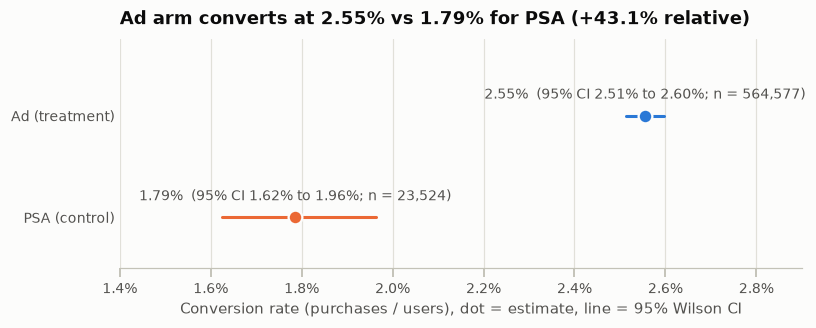

In [13]:
fig, ax = plt.subplots(figsize=(8, 2.7))
arm_rows = [("PSA (control)", x_psa, n_psa, PSA_COLOR), ("Ad (treatment)", x_ad, n_ad, AD_COLOR)]
for y, (label, x, n, color) in enumerate(arm_rows):
    lo, hi = proportion_confint(x, n, alpha=ALPHA, method="wilson")
    ax.plot([lo, hi], [y, y], color=color, lw=2, solid_capstyle="round")
    ax.plot(x / n, y, "o", ms=9, color=color, mec=SURFACE, mew=1.5)
    ax.annotate(f"{x / n:.2%}  (95% CI {lo:.2%} to {hi:.2%}; n = {n:,})", (x / n, y),
                xytext=(0, 9), textcoords="offset points", ha="center", va="bottom", color=INK_2, fontsize=9)
ax.set_yticks([0, 1], [row[0] for row in arm_rows])
ax.set_ylim(-0.5, 1.75)
ax.set_xlim(0.014, 0.029)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.grid(axis="x")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Conversion rate (purchases / users), dot = estimate, line = 95% Wilson CI")
ax.set_title(f"Ad arm converts at {cr_ad:.2%} vs {cr_psa:.2%} for PSA ({rel_lift:+.1%} relative)")
save(fig, "01_conversion_by_arm.png")
plt.show()

### Robustness: could the delivery-mix differences explain the lift?

Re-weight the PSA arm so its day, hour or exposure mix matches the ad arm's (direct standardization), then recompute the lift. If the small imbalances from Section 2 were driving the result, the re-weighted lift would move materially.

In [14]:
def reweighted_lift(by):
    # Ad rate minus the PSA rate re-weighted to the ad arm's distribution of `by`
    psa_rates = df[~is_ad].groupby(by, observed=True)["converted"].mean()
    ad_mix = df.loc[is_ad, by].value_counts(normalize=True)
    return cr_ad - (psa_rates * ad_mix).sum()


robustness = pd.Series({
    "unadjusted": abs_lift,
    "PSA re-weighted to the ad arm's day mix": reweighted_lift("most_ads_day"),
    "PSA re-weighted to the ad arm's hour mix": reweighted_lift("most_ads_hour"),
    "PSA re-weighted to the ad arm's exposure-bucket mix": reweighted_lift("exposure_bucket"),
}, name="absolute lift (pp)") * 100
max_shift = (robustness - robustness["unadjusted"]).abs().max()
print(f"Largest change from re-weighting: {max_shift:.2f} pp")
robustness.round(2).to_frame()

Largest change from re-weighting: 0.03 pp


,absolute lift (pp)
unadjusted,0.77
PSA re-weighted to the ad arm's day mix,0.78
PSA re-weighted to the ad arm's hour mix,0.78
PSA re-weighted to the ad arm's exposure-bucket mix,0.80


**Result:** the ad arm converts at 2.55% vs 1.79% for the PSA arm, a lift of **+0.77 pp (+43.1% relative)**. The 95% CI runs from +0.59 to +0.94 pp, with p = 1.7e-13. The chi-square test gives the same answer, and re-weighting for the delivery-mix differences moves the lift by at most 0.03 pp. The lift is real. Whether it is *big enough to pay for itself* is the subject of Section 6.

## 4. Power analysis: what could this test detect?

The PSA arm is only 23,524 users, so it sets the limit on precision. The **minimum detectable effect (MDE)** is the smallest true lift the test would catch 80% of the time at α = 0.05 (two-sided), given the actual arm sizes and the PSA baseline rate. `statsmodels` `NormalIndPower` solves for Cohen's *h*, an arcsine-scaled difference in proportions, which is then converted back to conversion-rate units.

In [15]:
def mde(n_control, ratio, baseline, alpha=ALPHA, power=POWER):
    # Smallest absolute lift over `baseline` detectable with n_control users and ratio = n_treatment / n_control
    h = NormalIndPower().solve_power(effect_size=None, nobs1=n_control, ratio=ratio,
                                     alpha=alpha, power=power, alternative="two-sided")
    return np.sin(np.arcsin(np.sqrt(baseline)) + float(h) / 2) ** 2 - baseline


ratio = n_ad / n_psa
mde_abs = mde(n_psa, ratio, cr_psa)
print(f"PSA baseline conversion rate {cr_psa:.2%}; allocation ad:PSA = {ratio:.1f}:1")
print(f"MDE: {mde_abs * 100:+.2f} pp absolute = {mde_abs / cr_psa:+.1%} relative")
print(f"Observed lift: {abs_lift * 100:+.2f} pp = {abs_lift / mde_abs:.1f}x the MDE")

designs = pd.DataFrame([
    (f"Actual: {n_ad:,} ad / {n_psa:,} PSA", n_psa, ratio),
    (f"Same {n_psa:,}-user PSA arm, unlimited ad users", n_psa, 1e6),
    (f"Same {n_total:,} users split 50/50", n_total / 2, 1.0),
], columns=["design", "psa_users", "ratio"]).set_index("design")
designs["MDE (pp)"] = [mde(n, r, cr_psa) * 100 for n, r in zip(designs["psa_users"], designs["ratio"])]
designs["MDE (relative)"] = designs["MDE (pp)"] / 100 / cr_psa
designs["vs actual"] = designs["MDE (pp)"] / designs["MDE (pp)"].iloc[0]
table(designs[["MDE (pp)", "MDE (relative)", "vs actual"]].style.format(
    {"MDE (pp)": "{:+.2f}", "MDE (relative)": "{:+.1%}", "vs actual": "{:.2f}x"}), "designs")

PSA baseline conversion rate 1.79%; allocation ad:PSA = 24.0:1
MDE: +0.26 pp absolute = +14.3% relative
Observed lift: +0.77 pp = 3.0x the MDE


,MDE (pp),MDE (relative),vs actual
design,,,
"Actual: 564,577 ad / 23,524 PSA",+0.26,+14.3%,1.00x
"Same 23,524-user PSA arm, unlimited ad users",+0.25,+14.0%,0.98x
"Same 588,101 users split 50/50",+0.10,+5.5%,0.38x


Full test: 23,524 PSA users -> MDE +14% relative
Median day segment: 3,490 PSA users -> MDE +39% relative
Median hour segment: 1,079 PSA users -> MDE +75% relative


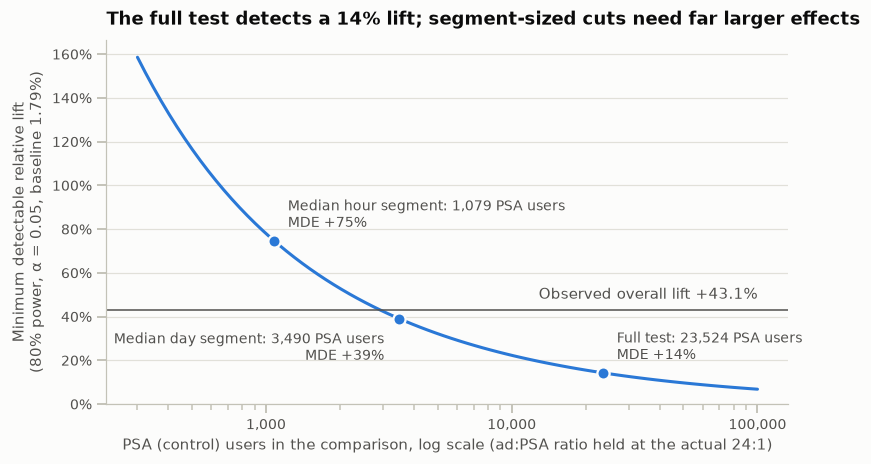

In [16]:
psa = df[~is_ad]
typical_segments = {
    "Median day segment": psa["most_ads_day"].value_counts().median(),
    "Median hour segment": psa["most_ads_hour"].value_counts().median(),
}
psa_sizes = np.geomspace(300, 100_000, 80)
mde_rel_curve = np.array([mde(n, ratio, cr_psa) for n in psa_sizes]) / cr_psa

fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(psa_sizes, mde_rel_curve, color=AD_COLOR, lw=2, solid_capstyle="round")
ax.axhline(rel_lift, color=INK_2, lw=1)
ax.annotate(f"Observed overall lift {rel_lift:+.1%}", (psa_sizes[-1], rel_lift), xytext=(0, 5),
            textcoords="offset points", ha="right", va="bottom", color=INK_2)
label_offsets = {"Full test": (9, 6, "left", "bottom"), "Median day segment": (-10, -8, "right", "top"),
                 "Median hour segment": (9, 6, "left", "bottom")}
for label, n in {"Full test": n_psa, **typical_segments}.items():
    m = mde(n, ratio, cr_psa) / cr_psa
    print(f"{label}: {n:,.0f} PSA users -> MDE {m:+.0%} relative")
    dx, dy, ha, va = label_offsets[label]
    ax.plot(n, m, "o", ms=8, color=AD_COLOR, mec=SURFACE, mew=1.5, zorder=3)
    ax.annotate(f"{label}: {n:,.0f} PSA users\nMDE {m:+.0%}", (n, m), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va=va, color=INK_2, fontsize=9)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, mde_rel_curve.max() * 1.05)
ax.grid(axis="y")
ax.set_xlabel("PSA (control) users in the comparison, log scale (ad:PSA ratio held at the actual 24:1)")
ax.set_ylabel(f"Minimum detectable relative lift\n(80% power, α = 0.05, baseline {cr_psa:.2%})")
ax.set_title(f"The full test detects a {mde_abs / cr_psa:.0%} lift; segment-sized cuts need far larger effects")
save(fig, "02_mde_by_control_size.png")
plt.show()

**Result:** at full size the test can detect a lift of about +0.26 pp (+14.3% relative). The observed +0.77 pp is 3.0x that, so the test was well powered for the effect it found. Two design lessons:

- **The PSA arm is the bottleneck.** Unlimited ad users would barely shrink the MDE (0.98x). A 50/50 split of the same users would detect effects 0.38x the size, but only by withholding the ad from half the audience during the test. The 96/4 design deliberately trades precision for reach.
- **Segment cuts are underpowered.** A median day segment has 3,490 PSA users and a median hour segment 1,079, so their MDEs are far larger (chart). In Section 5, "not significant" in a segment mostly means "not measurable", not "no effect".

## 5. Segments: where does the lift come from?

Each cut compares ad vs PSA *within* the segment:

| Cut | Segments | Note |
|---|---|---|
| Day the user saw the most ads | 7 | |
| Hour the user saw the most ads | 24 | night hours have tiny PSA cells, some with zero conversions |
| Total ads seen | 6 | buckets 1-5, 6-10, 11-20, 21-50, 51-100, 101+ |

**Multiple comparisons.** Running 37 tests at α = 0.05 invites false positives. Holm's step-down correction is applied across all 37, which controls the family-wise error rate with the same guarantee as Bonferroni and never rejects less. Segments that are significant before correction but not after are **flagged**.

**Per-segment test.** These use Fisher's exact test rather than the z-test, because the smallest cells (down to 23 PSA users with 0 conversions) are too small for the normal approximation. The CIs are Newcombe 95% intervals and are not adjusted for multiplicity.

In [17]:
SEGMENT_CUTS = {
    "most_ads_day": "Day with most ads",
    "most_ads_hour": "Hour with most ads",
    "exposure_bucket": "Total ads seen",
}
SEGMENT_LABEL = {
    "most_ads_day": str,
    "most_ads_hour": lambda h: f"{int(h):02d}:00",
    "exposure_bucket": lambda b: f"{b} ads",
}


def segment_tests(cut):
    counts = (df.groupby([cut, "test_group"], observed=True)["converted"]
                .agg(conversions="sum", users="size")
                .unstack("test_group"))
    rows = []
    for segment, c in counts.iterrows():
        xa, na = c[("conversions", "ad")], c[("users", "ad")]
        xp, npsa = c[("conversions", "psa")], c[("users", "psa")]
        ci_low, ci_high = confint_proportions_2indep(xa, na, xp, npsa, compare="diff", method="newcomb", alpha=ALPHA)
        rows.append({
            "cut": cut, "segment": segment, "ad_users": na, "psa_users": npsa,
            "psa_conversions": xp, "ad_cr": xa / na, "psa_cr": xp / npsa,
            "abs_lift": xa / na - xp / npsa, "ci_low": ci_low, "ci_high": ci_high,
            "p_value": stats.fisher_exact([[xa, na - xa], [xp, npsa - xp]]).pvalue,
        })
    return pd.DataFrame(rows)


seg = pd.concat([segment_tests(cut) for cut in SEGMENT_CUTS], ignore_index=True)
seg["rel_lift"] = (seg["ad_cr"] / seg["psa_cr"] - 1).replace(np.inf, np.nan)  # undefined when PSA has 0 conversions
seg["p_holm"] = multipletests(seg["p_value"], alpha=ALPHA, method="holm")[1]
seg["verdict"] = np.select(
    [seg["p_holm"] < ALPHA, seg["p_value"] < ALPHA],
    ["significant after Holm", "FLAG: fails Holm"],
    default="not significant",
)

n_raw = int((seg["p_value"] < ALPHA).sum())
n_holm = int((seg["p_holm"] < ALPHA).sum())
print(f"{len(seg)} segment tests. If no segment had a real lift, about {len(seg) * ALPHA:.2f} would still pass p < {ALPHA} by chance.")
print(f"Significant before correction: {n_raw} | significant after Holm: {n_holm} | flagged (fail Holm): {n_raw - n_holm}")
print(f"(Bonferroni would require p < {ALPHA / len(seg):.5f} for every test; Holm relaxes this step by step.)")
print()
for cut, label in SEGMENT_CUTS.items():
    rows = seg[seg["cut"] == cut]
    survivors = rows.loc[rows["verdict"] == "significant after Holm", "segment"].map(SEGMENT_LABEL[cut]).tolist()
    flagged = rows.loc[rows["verdict"] == "FLAG: fails Holm", "segment"].map(SEGMENT_LABEL[cut]).tolist()
    print(f"{label:<20} significant after Holm: {', '.join(survivors) or 'none'}")
    print(f"{'':<20} FLAGGED (significant only before correction): {', '.join(flagged) or 'none'}")

pd.crosstab(seg["cut"].map(SEGMENT_CUTS), seg["verdict"]).rename_axis(index="cut", columns=None)

37 segment tests. If no segment had a real lift, about 1.85 would still pass p < 0.05 by chance.
Significant before correction: 16 | significant after Holm: 7 | flagged (fail Holm): 9
(Bonferroni would require p < 0.00135 for every test; Holm relaxes this step by step.)

Day with most ads    significant after Holm: Monday, Tuesday, Wednesday
                     FLAGGED (significant only before correction): Friday, Saturday
Hour with most ads   significant after Holm: 14:00
                     FLAGGED (significant only before correction): 00:00, 09:00, 10:00, 11:00, 12:00, 13:00, 20:00
Total ads seen       significant after Holm: 21-50 ads, 51-100 ads, 101+ ads
                     FLAGGED (significant only before correction): none


,FLAG: fails Holm,not significant,significant after Holm
cut,,,
Day with most ads,2,2,3
Hour with most ads,7,16,1
Total ads seen,0,3,3


In [18]:
def pp(v):
    return f"{v * 100:+.2f} pp"


def segment_table(cut):
    cols = ["ad_users", "psa_users", "psa_conversions", "ad_cr", "psa_cr", "abs_lift",
            "ci_low", "ci_high", "rel_lift", "p_value", "p_holm", "verdict"]
    styled = (seg[seg["cut"] == cut].set_index("segment")[cols]
                .rename_axis(SEGMENT_CUTS[cut])
                .style.format({
                    "ad_users": "{:,}", "psa_users": "{:,}", "psa_conversions": "{:,}",
                    "ad_cr": "{:.2%}", "psa_cr": "{:.2%}", "abs_lift": pp, "ci_low": pp, "ci_high": pp,
                    "rel_lift": "{:+.0%}", "p_value": "{:.2g}", "p_holm": "{:.2g}",
                }, na_rep="n/a"))
    return table(styled, cut)


segment_table("most_ads_day")

,ad_users,psa_users,psa_conversions,ad_cr,psa_cr,abs_lift,ci_low,ci_high,rel_lift,p_value,p_holm,verdict
Day with most ads,,,,,,,,,,,,
Monday,"83,571","3,502",79,3.32%,2.26%,+1.07 pp,+0.51 pp,+1.53 pp,+47%,0.00033,0.011,significant after Holm
Tuesday,"74,572","2,907",42,3.04%,1.44%,+1.60 pp,+1.08 pp,+1.99 pp,+111%,6e-08,2.2e-06,significant after Holm
Wednesday,"77,418","3,490",55,2.54%,1.58%,+0.96 pp,+0.48 pp,+1.34 pp,+61%,0.00019,0.0066,significant after Holm
Thursday,"79,077","3,905",79,2.16%,2.02%,+0.14 pp,-0.36 pp,+0.55 pp,+7%,0.61,1,not significant
Friday,"88,805","3,803",62,2.25%,1.63%,+0.62 pp,+0.15 pp,+0.99 pp,+38%,0.0097,0.28,FLAG: fails Holm
Saturday,"78,802","2,858",40,2.13%,1.40%,+0.73 pp,+0.22 pp,+1.12 pp,+52%,0.0064,0.19,FLAG: fails Holm
Sunday,"82,332","3,059",63,2.46%,2.06%,+0.40 pp,-0.17 pp,+0.86 pp,+20%,0.17,1,not significant


In [19]:
segment_table("most_ads_hour")

,ad_users,psa_users,psa_conversions,ad_cr,psa_cr,abs_lift,ci_low,ci_high,rel_lift,p_value,p_holm,verdict
Hour with most ads,,,,,,,,,,,,
0,"5,309",227,0,1.92%,0.00%,+1.92 pp,+0.22 pp,+2.33 pp,n/a,0.022,0.55,FLAG: fails Holm
1,"4,615",187,0,1.34%,0.00%,+1.34 pp,-0.69 pp,+1.72 pp,n/a,0.18,1,not significant
2,"5,152",181,0,0.76%,0.00%,+0.76 pp,-1.33 pp,+1.03 pp,n/a,0.64,1,not significant
3,"2,590",89,1,1.04%,1.12%,-0.08 pp,-5.06 pp,+0.96 pp,-7%,0.61,1,not significant
4,694,28,0,1.59%,0.00%,+1.59 pp,-10.50 pp,+2.82 pp,n/a,1,1,not significant
5,742,23,0,2.16%,0.00%,+2.16 pp,-12.18 pp,+3.47 pp,n/a,1,1,not significant
6,"1,985",83,0,2.32%,0.00%,+2.32 pp,-2.14 pp,+3.08 pp,n/a,0.26,1,not significant
7,"6,168",237,2,1.85%,0.84%,+1.00 pp,-1.20 pp,+1.72 pp,+119%,0.45,1,not significant
8,"16,968",659,7,1.99%,1.06%,+0.92 pp,-0.21 pp,+1.51 pp,+87%,0.11,1,not significant


In [20]:
segment_table("exposure_bucket")

,ad_users,psa_users,psa_conversions,ad_cr,psa_cr,abs_lift,ci_low,ci_high,rel_lift,p_value,p_holm,verdict
Total ads seen,,,,,,,,,,,,
1-5,"169,962","7,861",22,0.25%,0.28%,-0.03 pp,-0.17 pp,+0.07 pp,-10%,0.57,1,not significant
6-10,"79,537","3,415",23,0.49%,0.67%,-0.19 pp,-0.53 pp,+0.04 pp,-28%,0.13,1,not significant
11-20,"123,334","4,150",34,0.84%,0.82%,+0.02 pp,-0.31 pp,+0.26 pp,+3%,1,1,not significant
21-50,"125,541","5,235",114,2.92%,2.18%,+0.74 pp,+0.30 pp,+1.11 pp,+34%,0.0013,0.042,significant after Holm
51-100,"44,149","1,853",107,11.63%,5.77%,+5.86 pp,+4.66 pp,+6.88 pp,+101%,4e-17,1.5e-15,significant after Holm
101+,"22,054","1,010",120,17.14%,11.88%,+5.25 pp,+3.06 pp,+7.17 pp,+44%,6.3e-06,0.00022,significant after Holm


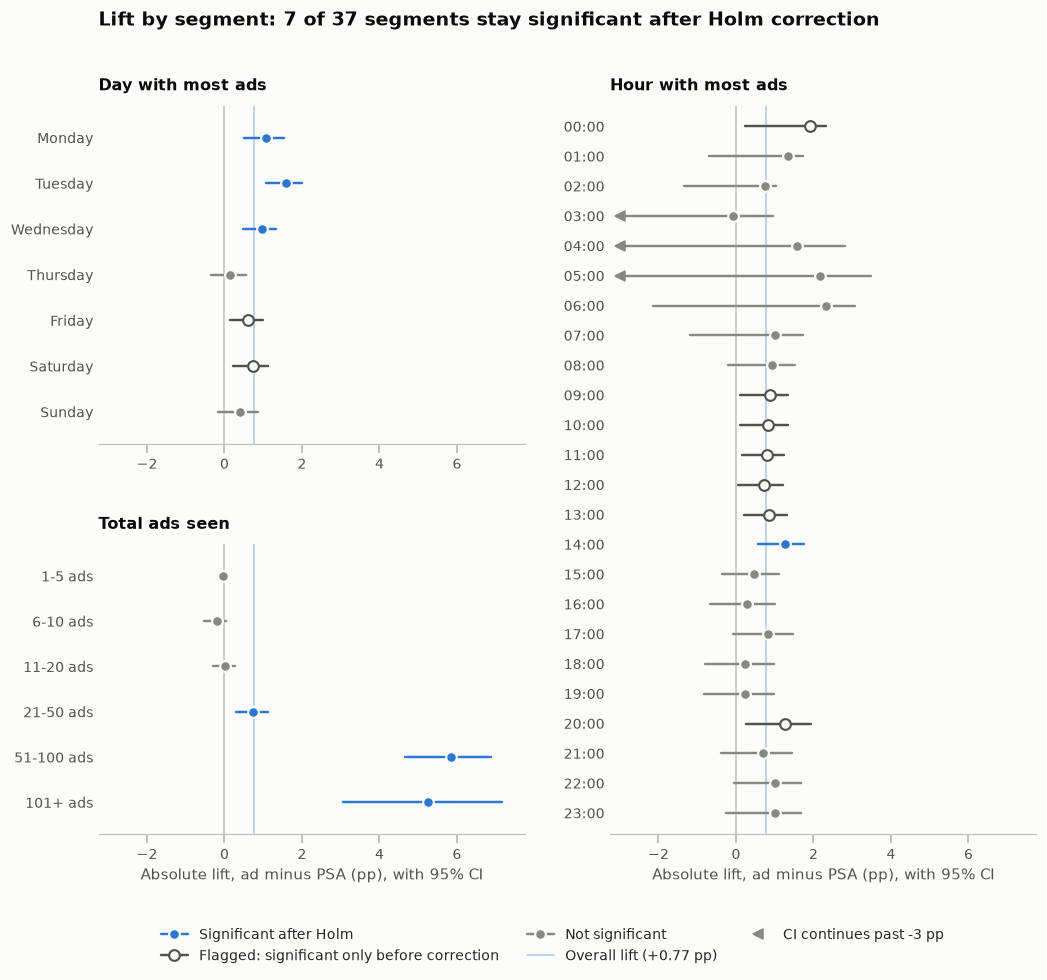

In [21]:
VERDICT_STYLE = {  # emphasis: the accent hue marks confirmed lifts, greys for everything else
    "significant after Holm": dict(line=AD_COLOR, face=AD_COLOR, edge=SURFACE, label="Significant after Holm"),
    "FLAG: fails Holm": dict(line=INK_2, face=SURFACE, edge=INK_2, label="Flagged: significant only before correction"),
    "not significant": dict(line=MUTED, face=MUTED, edge=SURFACE, label="Not significant"),
}
X_CLIP = (-3.0, 7.5)  # pp; CIs that run past the left edge are clipped and marked with an arrow


def forest_panel(ax, cut):
    t = seg[seg["cut"] == cut].reset_index(drop=True)
    ys = np.arange(len(t))[::-1]
    ax.axvline(0, color=AXIS, lw=1, zorder=1)
    ax.axvline(abs_lift * 100, color=AD_COLOR, lw=1, alpha=0.4, zorder=1)
    for y, r in zip(ys, t.itertuples(index=False)):
        st = VERDICT_STYLE[r.verdict]
        lo, hi = r.ci_low * 100, r.ci_high * 100
        ax.plot([max(lo, X_CLIP[0]), min(hi, X_CLIP[1])], [y, y], color=st["line"], lw=1.6,
                solid_capstyle="round", zorder=2)
        if lo < X_CLIP[0]:
            ax.plot(X_CLIP[0], y, marker="<", ms=6, color=st["line"], zorder=2)
        ax.plot(r.abs_lift * 100, y, "o", ms=7, mfc=st["face"], mec=st["edge"], mew=1.4, zorder=3)
    ax.set_yticks(ys, [SEGMENT_LABEL[cut](s) for s in t["segment"]])
    ax.set_ylim(-0.7, len(t) - 0.3)
    ax.set_xlim(X_CLIP[0] - 0.25, X_CLIP[1] + 0.25)
    ax.set_title(SEGMENT_CUTS[cut], fontsize=10.5)
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)


fig = plt.figure(figsize=(11, 8.6))
grid = fig.add_gridspec(2, 2, height_ratios=[7, 6], hspace=0.32, wspace=0.2)
ax_day, ax_exp, ax_hour = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[:, 1])
forest_panel(ax_day, "most_ads_day")
forest_panel(ax_exp, "exposure_bucket")
forest_panel(ax_hour, "most_ads_hour")
for ax in (ax_exp, ax_hour):
    ax.set_xlabel("Absolute lift, ad minus PSA (pp), with 95% CI")

handles = [Line2D([], [], color=s["line"], lw=1.6, marker="o", ms=7, mfc=s["face"], mec=s["edge"], mew=1.4, label=s["label"])
           for s in VERDICT_STYLE.values()]
handles += [Line2D([], [], color=AD_COLOR, alpha=0.4, lw=1, label=f"Overall lift ({abs_lift * 100:+.2f} pp)"),
            Line2D([], [], color=MUTED, marker="<", ls="", ms=6, label=f"CI continues past {X_CLIP[0]:.0f} pp")]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"Lift by segment: {n_holm} of {len(seg)} segments stay significant after Holm correction",
             x=0.125, ha="left", fontsize=12.5, fontweight="bold", color=INK)
save(fig, "03_segment_lift_forest.png")
plt.show()

### A closer look at exposure

Two facts have to be read together. First, the lift sits almost entirely in the high-exposure buckets. Second, *both* arms convert far more as exposure rises.

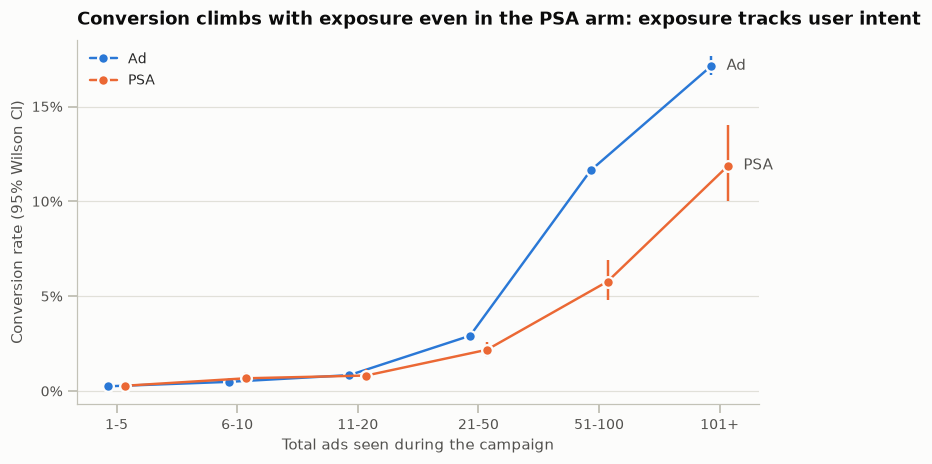

In [22]:
by_bucket = df.groupby(["exposure_bucket", "test_group"], observed=True)["converted"].agg(conversions="sum", users="size")
xs = np.arange(len(EXPOSURE_LABELS))

fig, ax = plt.subplots(figsize=(8, 4.3))
for offset, arm, color, name in [(-0.07, "ad", AD_COLOR, "Ad"), (0.07, "psa", PSA_COLOR, "PSA")]:
    t = by_bucket.xs(arm, level="test_group").reindex(EXPOSURE_LABELS)
    rate = t["conversions"] / t["users"]
    lo, hi = proportion_confint(t["conversions"], t["users"], alpha=ALPHA, method="wilson")
    ax.vlines(xs + offset, lo, hi, color=color, lw=1.6)
    ax.plot(xs + offset, rate, color=color, lw=1.6, marker="o", ms=7, mec=SURFACE, mew=1.5, label=name)
    ax.annotate(name, (xs[-1] + offset, rate.iloc[-1]), xytext=(10, 0), textcoords="offset points",
                va="center", color=INK_2)
ax.set_xticks(xs, EXPOSURE_LABELS)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.grid(axis="y")
ax.legend(loc="upper left")
ax.set_xlabel("Total ads seen during the campaign")
ax.set_ylabel("Conversion rate (95% Wilson CI)")
ax.set_title("Conversion climbs with exposure even in the PSA arm: exposure tracks user intent")
save(fig, "04_conversion_by_exposure.png")
plt.show()

In [23]:
exp_seg = seg[seg["cut"] == "exposure_bucket"].assign(segment=lambda t: t["segment"].astype(str)).set_index("segment")
light_buckets = ["1-5", "6-10", "11-20"]
light = exp_seg.loc[light_buckets]
ruled_out = pd.DataFrame({
    "PSA conversion rate": light["psa_cr"],
    f"lift if the overall {rel_lift:+.1%} applied": light["psa_cr"] * rel_lift,
    "upper end of the 95% CI": light["ci_high"],
})
ruled_out["overall relative lift ruled out?"] = ruled_out["upper end of the 95% CI"] < ruled_out.iloc[:, 1]

share_light = df.loc[is_ad, "exposure_bucket"].isin(light_buckets).mean()
day_hour = seg[seg["cut"].isin(["most_ads_day", "most_ads_hour"])]
covers_overall = ((day_hour["ci_low"] <= abs_lift) & (day_hour["ci_high"] >= abs_lift)).sum()
print(f"Share of ad-arm users with 20 or fewer ads: {share_light:.1%}")
print(f"PSA conversion rate, 1-5 ads -> 101+ ads: {exp_seg.loc['1-5', 'psa_cr']:.2%} -> {exp_seg.loc['101+', 'psa_cr']:.2%}")
print(f"Day/hour segments whose 95% CI contains the overall lift: {covers_overall} of {len(day_hour)}")
table(ruled_out.style.format({c: pp for c in ruled_out.columns[1:3]}).format("{:.2%}", subset=["PSA conversion rate"]), "ruled_out")

Share of ad-arm users with 20 or fewer ads: 66.0%
PSA conversion rate, 1-5 ads -> 101+ ads: 0.28% -> 11.88%
Day/hour segments whose 95% CI contains the overall lift: 29 of 31


,PSA conversion rate,lift if the overall +43.1% applied,upper end of the 95% CI,overall relative lift ruled out?
segment,,,,
1-5,0.28%,+0.12 pp,+0.07 pp,True
6-10,0.67%,+0.29 pp,+0.04 pp,True
11-20,0.82%,+0.35 pp,+0.26 pp,True


**Reading the segment results.** These cuts are observational, so treat them as hypotheses for the next test rather than conclusions.

- **The lift shows up at high exposure.** Users who saw 20 or fewer ads (66.0% of the ad arm) show no detectable lift. In each of those buckets the CI is tight enough to rule out the overall +43.1% relative lift. The lift appears at 21-50 ads and is large at 51 or more.
- **But exposure is confounded with intent.** PSA users also convert far more as exposure rises (0.28% at 1-5 ads, 11.88% at 101+), and a PSA can't sell the product. Heavy-exposure users are simply more active, higher-intent visitors. So the exposure gradient is not a dose-response curve, and nothing here says that showing *more* ads to light users would lift them.
- **Exposure is also post-treatment.** It is counted over the whole campaign, so a purchase can come before some of the impressions, and buyers who keep browsing pile up impressions in both arms. That can drain converters out of the low buckets and exaggerate how concentrated the lift looks. Only a randomized frequency test can separate "the ad needs repetition" from "engaged users see more ads".
- **Day and hour.** Monday, Tuesday and Wednesday stay significant after Holm, Friday and Saturday are flagged, and Thursday and Sunday are not significant. Among hours only 14:00 survives, and seven other hours are flagged. A segment being significant while another is not doesn't mean their lifts differ: 29 of the 31 day and hour CIs contain the overall lift, and hour cells are badly underpowered (Section 4). None of this justifies dayparting yet.

## 6. Business translation

### Incremental purchases

The absolute lift converts directly into incremental purchases. For every 1,000 users exposed, the ad produces `lift x 1,000` purchases that would not have happened with the PSA.

In [24]:
ads_per_user = df.loc[is_ad, "total_ads"].mean()
incr_per_1k = abs_lift * 1000
incr_per_1k_ci = (abs_ci[0] * 1000, abs_ci[1] * 1000)
incr_in_test = abs_lift * n_ad
incr_in_test_ci = (abs_ci[0] * n_ad, abs_ci[1] * n_ad)

print(f"Incremental purchases per 1,000 users exposed: {incr_per_1k:.2f} (95% CI {incr_per_1k_ci[0]:.2f} to {incr_per_1k_ci[1]:.2f})")
print(f"Ad impressions per 1,000 users exposed:        {ads_per_user * 1000:,.0f} (mean {ads_per_user:.2f} ads per ad-arm user)")
print(f"Incremental purchases per 1,000 impressions:   {incr_per_1k / ads_per_user:.2f}")
print()
print(f"In the test: {incr_in_test:,.0f} of the ad arm's {x_ad:,} purchases were incremental "
      f"(95% CI {incr_in_test_ci[0]:,.0f} to {incr_in_test_ci[1]:,.0f}), i.e. {abs_lift / cr_ad:.1%}.")
print(f"The other {1 - abs_lift / cr_ad:.1%} would have happened without the ad.")

Incremental purchases per 1,000 users exposed: 7.69 (95% CI 5.87 to 9.36)
Ad impressions per 1,000 users exposed:        24,823 (mean 24.82 ads per ad-arm user)
Incremental purchases per 1,000 impressions:   0.31

In the test: 4,343 of the ad arm's 14,423 purchases were incremental (95% CI 3,316 to 5,284), i.e. 30.1%.
The other 69.9% would have happened without the ad.


That last line is the attribution trap. Last-click attribution would credit all 14,423 ad-arm purchases to the ad, but only about 30.1% of them were *caused* by it. The rest came from users who would have bought anyway.

### Break-even analysis, built on ASSUMPTIONS

> **The dataset contains no cost or revenue data.** The cost-per-ad and revenue-per-conversion values below are **ASSUMPTIONS**, chosen only to span a plausible range. They are not facts about this campaign. Replace them with the real CPM and, ideally, the real *margin* per conversion before using this for a decision.

- Ad spend per 1,000 users exposed = ad impressions per 1,000 users × **ASSUMED** cost per ad
- Incremental revenue per 1,000 users = incremental purchases per 1,000 users × **ASSUMED** revenue per conversion
- **Break-even revenue per conversion** = ad spend per 1,000 users ÷ incremental purchases per 1,000 users

In [25]:
# ==========================================================================================
# ASSUMPTIONS: NOT FROM THE DATA. Illustrative values only; replace with real figures.
# ==========================================================================================
ASSUMED_COST_PER_AD = [0.001, 0.0025, 0.005, 0.01, 0.02]  # $ per ad impression, i.e. $1 to $20 CPM
ASSUMED_REVENUE_PER_CONVERSION = [5, 10, 25, 50, 100]     # $ per purchase

In [26]:
def spend_per_1k_users(cost_per_ad):
    return ads_per_user * 1000 * cost_per_ad


breakeven = pd.DataFrame({
    "ASSUMED cost per ad": ASSUMED_COST_PER_AD,
    "same as CPM": [c * 1000 for c in ASSUMED_COST_PER_AD],
    "ad spend per 1,000 users": [spend_per_1k_users(c) for c in ASSUMED_COST_PER_AD],
    "break-even revenue per conversion": [spend_per_1k_users(c) / incr_per_1k for c in ASSUMED_COST_PER_AD],
    "conservative (lift at CI low)": [spend_per_1k_users(c) / incr_per_1k_ci[0] for c in ASSUMED_COST_PER_AD],
    "optimistic (lift at CI high)": [spend_per_1k_users(c) / incr_per_1k_ci[1] for c in ASSUMED_COST_PER_AD],
})
be_per_cpm = ads_per_user / 1000 / abs_lift  # break-even revenue per conversion for each $1 of CPM
be_per_cpm_conservative = ads_per_user / 1000 / abs_ci[0]
print(f"Rule of thumb: break-even revenue per conversion = ${be_per_cpm:.2f} per $1 of CPM "
      f"(conservative ${be_per_cpm_conservative:.2f}, optimistic ${ads_per_user / 1000 / abs_ci[1]:.2f})")
table(breakeven.style
      .format({"ASSUMED cost per ad": "${:.4f}", "same as CPM": "${:.2f}"})
      .format("${:,.2f}", subset=breakeven.columns[2:])
      .hide(axis="index")
      .set_caption("Break-even revenue per conversion under ASSUMED ad costs"), "breakeven")

Rule of thumb: break-even revenue per conversion = $3.23 per $1 of CPM (conservative $4.23, optimistic $2.65)


ASSUMED cost per ad,same as CPM,"ad spend per 1,000 users",break-even revenue per conversion,conservative (lift at CI low),optimistic (lift at CI high)
$0.0010,$1.00,$24.82,$3.23,$4.23,$2.65
$0.0025,$2.50,$62.06,$8.07,$10.57,$6.63
$0.0050,$5.00,$124.12,$16.13,$21.13,$13.26
$0.0100,$10.00,$248.23,$32.27,$42.26,$26.52
$0.0200,$20.00,$496.47,$64.54,$84.53,$53.04


In [27]:
net_profit = pd.DataFrame(
    [[incr_per_1k * rev - spend_per_1k_users(cost) for rev in ASSUMED_REVENUE_PER_CONVERSION] for cost in ASSUMED_COST_PER_AD],
    index=pd.Index([f"${c:.4f} per ad (${c * 1000:.2f} CPM)" for c in ASSUMED_COST_PER_AD], name="ASSUMED cost per ad"),
    columns=pd.Index([f"${r}" for r in ASSUMED_REVENUE_PER_CONVERSION], name="ASSUMED revenue per conversion"),
)
table(net_profit.style.format("{:+,.0f}").set_caption(
    "Net incremental profit per 1,000 users exposed ($, point estimate; negative = the campaign loses money)"), "net_profit")

ASSUMED revenue per conversion,$5,$10,$25,$50,$100
ASSUMED cost per ad,,,,,
$0.0010 per ad ($1.00 CPM),+14,+52,+167,+360,+744
$0.0025 per ad ($2.50 CPM),-24,+15,+130,+323,+707
$0.0050 per ad ($5.00 CPM),-86,-47,+68,+261,+645
$0.0100 per ad ($10.00 CPM),-210,-171,-56,+136,+521
$0.0200 per ad ($20.00 CPM),-458,-420,-304,-112,+273


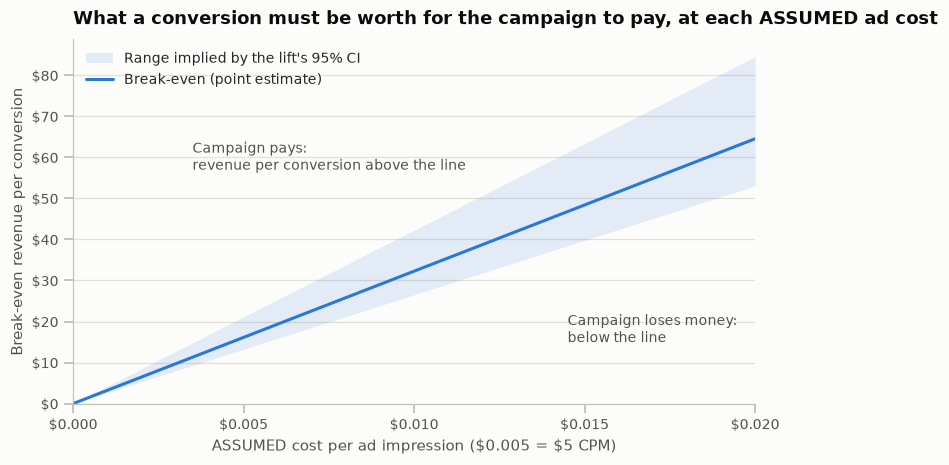

In [28]:
cost_grid = np.linspace(0, max(ASSUMED_COST_PER_AD), 200)
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.fill_between(cost_grid, ads_per_user * cost_grid / abs_ci[1], ads_per_user * cost_grid / abs_ci[0],
                color=AD_COLOR, alpha=0.12, lw=0, label="Range implied by the lift's 95% CI")
ax.plot(cost_grid, ads_per_user * cost_grid / abs_lift, color=AD_COLOR, lw=2, label="Break-even (point estimate)")
ax.text(0.0035, 60, "Campaign pays:\nrevenue per conversion above the line", color=INK_2, fontsize=9, va="center")
ax.text(0.0145, 18, "Campaign loses money:\nbelow the line", color=INK_2, fontsize=9, va="center")
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.005))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:.3f}"))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_xlim(0, max(ASSUMED_COST_PER_AD))
ax.set_ylim(0, ads_per_user * max(ASSUMED_COST_PER_AD) / abs_ci[0] * 1.05)
ax.grid(axis="y")
ax.legend(loc="upper left")
ax.set_xlabel(r"ASSUMED cost per ad impression (\$0.005 = \$5 CPM)")
ax.set_ylabel("Break-even revenue per conversion")
ax.set_title("What a conversion must be worth for the campaign to pay, at each ASSUMED ad cost")
save(fig, "05_break_even.png")
plt.show()

### Where the spend goes

Impressions are not spread evenly across users. The table below lines up each exposure bucket's share of impressions with its incremental purchases. These are point estimates on an observational cut, so the Section 5 caveats apply.

In [29]:
ad_exposure = (df[is_ad].groupby("exposure_bucket", observed=True)["total_ads"]
                 .agg(users="size", impressions="sum", ads_per_user="mean"))
ad_exposure.index = ad_exposure.index.astype(str)
spend_by_bucket = pd.DataFrame({
    "share of ad users": ad_exposure["users"] / ad_exposure["users"].sum(),
    "share of ad impressions": ad_exposure["impressions"] / ad_exposure["impressions"].sum(),
    "ads per user": ad_exposure["ads_per_user"],
    "incremental purchases per 1,000 users": exp_seg["abs_lift"] * 1000,
    "incremental purchases per 1,000 impressions": exp_seg["abs_lift"] * 1000 / ad_exposure["ads_per_user"],
    "Holm verdict": exp_seg["verdict"],
}).reindex(EXPOSURE_LABELS).rename_axis("total ads seen")

light_impressions = spend_by_bucket.loc[light_buckets, "share of ad impressions"].sum()
print(f"Users with 20 or fewer ads: {share_light:.1%} of ad users, {light_impressions:.1%} of ad impressions, no detectable lift")
print(f"Overall: {incr_per_1k / ads_per_user:.2f} incremental purchases per 1,000 impressions")
table(spend_by_bucket.style.format({
    "share of ad users": "{:.1%}", "share of ad impressions": "{:.1%}", "ads per user": "{:.1f}",
    "incremental purchases per 1,000 users": "{:+.2f}", "incremental purchases per 1,000 impressions": "{:+.2f}",
}), "spend_by_bucket")

Users with 20 or fewer ads: 66.0% of ad users, 20.9% of ad impressions, no detectable lift
Overall: 0.31 incremental purchases per 1,000 impressions


,share of ad users,share of ad impressions,ads per user,"incremental purchases per 1,000 users","incremental purchases per 1,000 impressions",Holm verdict
total ads seen,,,,,,
1-5,30.1%,3.2%,2.6,-0.29,-0.11,not significant
6-10,14.1%,4.3%,7.6,-1.88,-0.25,not significant
11-20,21.8%,13.5%,15.3,+0.21,+0.01,not significant
21-50,22.2%,28.2%,31.5,+7.38,+0.23,significant after Holm
51-100,7.8%,21.9%,69.4,+58.57,+0.84,significant after Holm
101+,3.9%,29.0%,184.0,+52.54,+0.29,significant after Holm


**Result:** the ad generates 7.69 incremental purchases per 1,000 users exposed (95% CI 5.87 to 9.36), bought with 24,823 impressions. It breaks even when a conversion is worth about $3.23 for every $1 of CPM, or $4.23 at the conservative end of the CI. At an **ASSUMED** $5 CPM that means at least $16.13 per conversion ($21.13 conservatively). Spend is uneven across exposure buckets:

- Users with 20 or fewer ads absorb 20.9% of impressions with no measurable return.
- The 101+ bucket takes 29.0% of impressions at 0.29 incremental purchases per 1,000 impressions, against 0.84 for the 51-100 bucket.

## 7. Recommendation

The headline numbers, all computed above:

In [30]:
headline = [
    ("Users (ad / PSA)", f"{n_ad:,} / {n_psa:,}"),
    ("Conversion rate (ad / PSA)", f"{cr_ad:.2%} / {cr_psa:.2%}"),
    ("Absolute lift (95% CI)", f"{abs_lift * 100:+.2f} pp ({abs_ci[0] * 100:+.2f} to {abs_ci[1] * 100:+.2f} pp)"),
    ("Relative lift (95% CI)", f"{rel_lift:+.1%} ({rel_ci[0]:+.1%} to {rel_ci[1]:+.1%})"),
    ("Two-proportion z-test", f"z = {z_stat:.2f}, p = {p_value:.1e}"),
    ("Chi-square confirmation", f"χ² = {chi2:.2f}, p = {chi2_p:.1e}"),
    ("Sample-ratio check vs 96/4 plan", f"p = {srm_p:.4f} (no mismatch)"),
    ("MDE at 80% power, α = 0.05", f"{mde_abs * 100:+.2f} pp ({mde_abs / cr_psa:+.1%} relative)"),
    ("Incremental purchases per 1,000 users exposed", f"{incr_per_1k:.2f} ({incr_per_1k_ci[0]:.2f} to {incr_per_1k_ci[1]:.2f})"),
    ("Ad impressions per 1,000 users exposed", f"{ads_per_user * 1000:,.0f}"),
    ("Break-even revenue per conversion", f"${be_per_cpm:.2f} per $1 CPM (conservative ${be_per_cpm_conservative:.2f})"),
    ("Segments significant after Holm", f"{n_holm} of {len(seg)} ({n_raw - n_holm} more flagged: significant only before correction)"),
]
width = max(len(metric) for metric, _ in headline)
print("HEADLINE RESULTS")
for metric, value in headline:
    print(f"  {metric:<{width}}  {value}")

HEADLINE RESULTS
  Users (ad / PSA)                               564,577 / 23,524
  Conversion rate (ad / PSA)                     2.55% / 1.79%
  Absolute lift (95% CI)                         +0.77 pp (+0.59 to +0.94 pp)
  Relative lift (95% CI)                         +43.1% (+30.0% to +57.5%)
  Two-proportion z-test                          z = 7.37, p = 1.7e-13
  Chi-square confirmation                        χ² = 54.32, p = 1.7e-13
  Sample-ratio check vs 96/4 plan                p = 0.9998 (no mismatch)
  MDE at 80% power, α = 0.05                     +0.26 pp (+14.3% relative)
  Incremental purchases per 1,000 users exposed  7.69 (5.87 to 9.36)
  Ad impressions per 1,000 users exposed         24,823
  Break-even revenue per conversion              $3.23 per $1 CPM (conservative $4.23)
  Segments significant after Holm                7 of 37 (9 more flagged: significant only before correction)


### Ship, with refined targeting

**1. Ship: the lift is real.** The ad raises conversion by +0.77 pp (+43.1% relative, p = 1.7e-13), which is 7.69 extra purchases per 1,000 users exposed. The result is 3.0x the test's MDE, the chi-square test confirms it, and it holds up to re-weighting for delivery differences. The campaign pays whenever a conversion is worth more than about $3.23 per $1 of CPM, or $4.23 per $1 to be conservative. Check that against the real CPM and margin before committing budget. If the real margin per conversion is below the conservative break-even, don't ship.

**2. Refine targeting before scaling spend, using randomized follow-ups rather than the observational cuts:**
- **Frequency cap test.** Randomize users to a cap of about 100 impressions vs no cap. The 101+ bucket absorbs 29.0% of impressions at 0.29 incremental purchases per 1,000 impressions, against 0.84 for the 51-100 bucket.
- **Light users.** Users with 20 or fewer ads (66.0% of users, 20.9% of impressions) show no measurable lift. Test whether moving that spend toward engaged audiences raises total incremental purchases.
- **No dayparting yet.** Day and hour effects mostly fail correction or are underpowered.

**3. Keep a holdout.** A standing PSA holdout of the same size keeps measuring incrementality and can detect relative lifts of about 14.3%.

### Caveats

- **Exposure-count confounding.** Conversion rises with exposure in *both* arms (PSA: 0.28% to 11.88%), so exposure mostly tracks user intent. The exposure-bucket lifts are not a dose-response curve.
- **Observational segment cuts.** Day, hour and exposure are all measured after assignment. If the ad changed browsing behaviour, a segment compares different kinds of users in each arm. Purchases can also come before later impressions, which is reverse causation.
- **Delivery mix.** The day and hour mix differs slightly between arms (Cramér's V of 0.020 and 0.018). Re-weighting moves the lift by at most 0.03 pp, so this does not change the conclusion.
- **Planned split unknown.** The SRM check assumes a 96/4 plan, inferred from the data.
- **No cost or margin data.** Every break-even figure rests on ASSUMED costs, and revenue overstates profit. With margin data the break-even rises.
- **Scope.** This is one campaign and one test window, and the outcome is purchase only. There is nothing on long-run effects, ad fatigue or cannibalization, and the public dataset has no timestamps.